# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

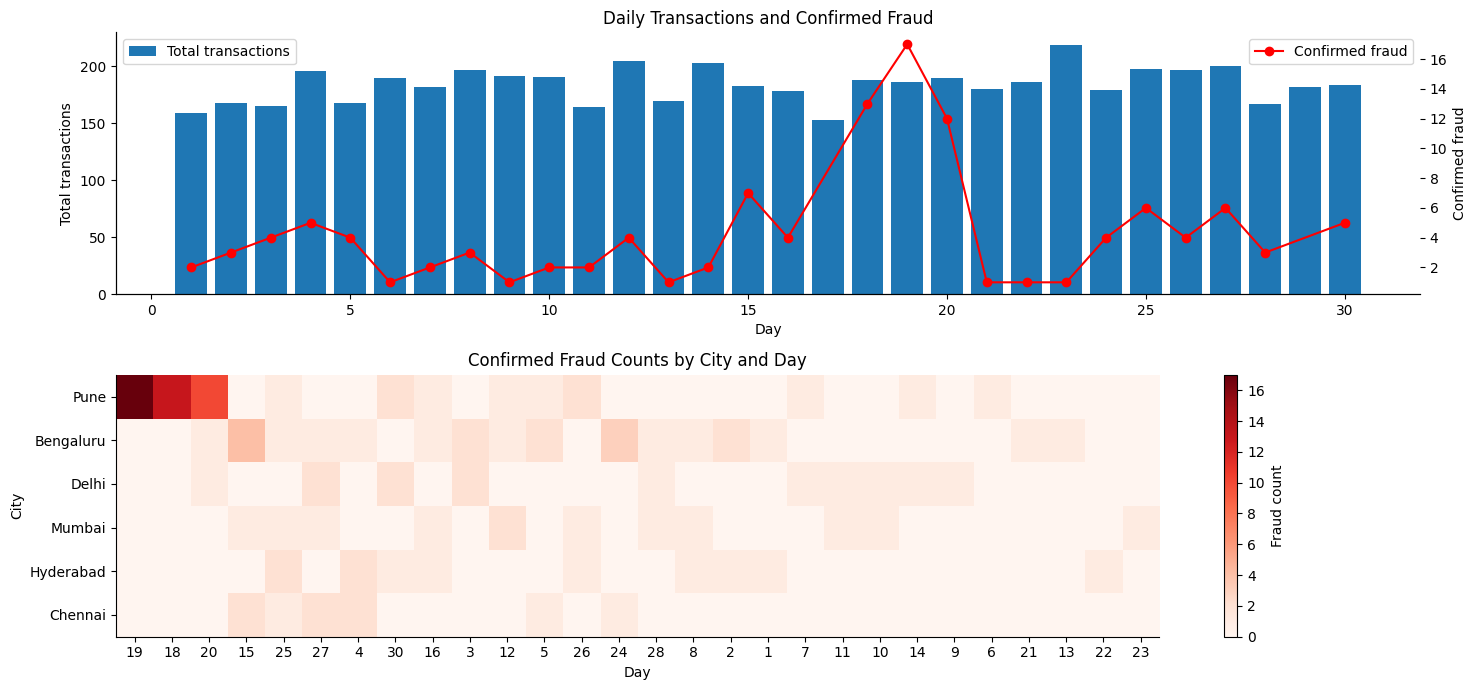

Top city-day cells by confirmed fraud count:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
           3       2
Pune       26      2
Bengaluru  5       2
Hyderabad  25      2
           4       2
dtype: int64


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))

# TODO 1: Daily transaction counts and confirmed fraud on a second axis
daily_txns = tx.groupby("day")["txn_id"].count()
daily_fraud = tx[tx["is_fraud"] == 1].groupby("day")["txn_id"].count()

axes[0].bar(daily_txns.index, daily_txns.values, label="Total transactions")
axes[0].set_xlabel("Day")
axes[0].set_ylabel("Total transactions")
axes[0].set_title("Daily Transactions and Confirmed Fraud")
axes[0].legend(loc="upper left")

ax2 = axes[0].twinx()
ax2.plot(daily_fraud.index, daily_fraud.values, color="red",
         marker="o", label="Confirmed fraud")
ax2.set_ylabel("Confirmed fraud")
ax2.legend(loc="upper right")

# TODO 2: City × day confirmed-fraud count matrix, reordered by totals
fraud = tx[tx["is_fraud"] == 1]
heat = pd.crosstab(fraud["city"], fraud["day"])

heat = heat.loc[
    heat.sum(axis=1).sort_values(ascending=False).index,
    heat.sum(axis=0).sort_values(ascending=False).index
]

im = axes[1].imshow(heat, aspect="auto", cmap="Reds")
axes[1].set_xticks(range(len(heat.columns)))
axes[1].set_xticklabels(heat.columns)
axes[1].set_yticks(range(len(heat.index)))
axes[1].set_yticklabels(heat.index)
axes[1].set_xlabel("Day")
axes[1].set_ylabel("City")
axes[1].set_title("Confirmed Fraud Counts by City and Day")
fig.colorbar(im, ax=axes[1], label="Fraud count")

plt.tight_layout()
plt.show()

# TODO 3: Print the city-day cells with the most fraud
top_cells = heat.stack().sort_values(ascending=False)
print("Top city-day cells by confirmed fraud count:")
print(top_cells.head(10))

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:The overview revealed patterns in fraud across days and cities, including clusters of high-fraud city–day combinations that an alert list sorted by detector score would not show. The lecture concept is reordering a matrix (Slide 39), which makes patterns easier to identify by sorting rows and columns by their totals._

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

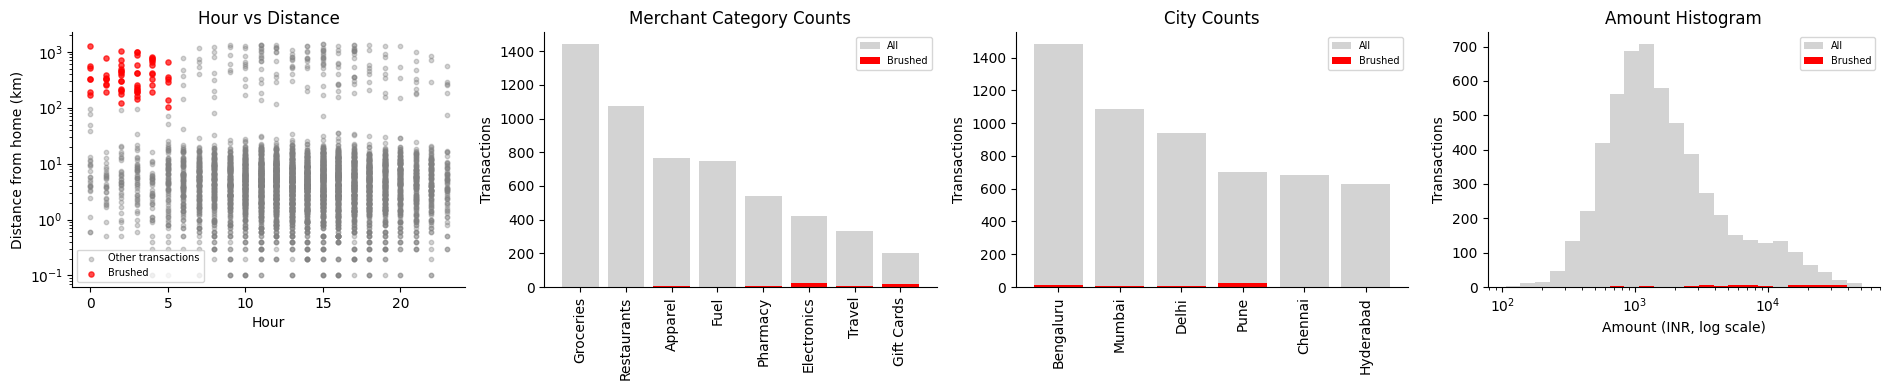

Number brushed: 61
Fraud rate inside brush: 86.89%
Overall fraud rate: 2.17%
Share of all fraud captured by brush: 44.17%


In [3]:
# TODO 1: Define the brush
brush = (tx["night"] == True) & (tx["distance_from_home_km"] > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))

# TODO 2(a): Hour vs. distance scatter (log y)
axes[0].scatter(
    tx.loc[~brush, "hour"], tx.loc[~brush, "distance_from_home_km"],
    color="grey", alpha=0.35, s=10, label="Other transactions"
)
axes[0].scatter(
    tx.loc[brush, "hour"], tx.loc[brush, "distance_from_home_km"],
    color="red", alpha=0.7, s=14, label="Brushed"
)
axes[0].set_yscale("log")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Distance from home (km)")
axes[0].set_title("Hour vs Distance")
axes[0].legend(fontsize=7)

# TODO 2(b): Merchant category counts
cat_all = tx["merchant_category"].value_counts()
cat_brush = tx.loc[brush, "merchant_category"].value_counts()
cat_order = cat_all.index

axes[1].bar(cat_order, cat_all.reindex(cat_order, fill_value=0),
            color="lightgrey", label="All")
axes[1].bar(cat_order, cat_brush.reindex(cat_order, fill_value=0),
            color="red", label="Brushed")
axes[1].set_title("Merchant Category Counts")
axes[1].set_ylabel("Transactions")
axes[1].tick_params(axis="x", rotation=90)
axes[1].legend(fontsize=7)

# TODO 2(c): City counts
city_all = tx["city"].value_counts()
city_brush = tx.loc[brush, "city"].value_counts()
city_order = city_all.index

axes[2].bar(city_order, city_all.reindex(city_order, fill_value=0),
            color="lightgrey", label="All")
axes[2].bar(city_order, city_brush.reindex(city_order, fill_value=0),
            color="red", label="Brushed")
axes[2].set_title("City Counts")
axes[2].set_ylabel("Transactions")
axes[2].tick_params(axis="x", rotation=90)
axes[2].legend(fontsize=7)

# TODO 2(d): Amount histogram (log10)
bins = np.logspace(
    np.log10(tx["amount_inr"].min()),
    np.log10(tx["amount_inr"].max()),
    25
)
axes[3].hist(tx["amount_inr"], bins=bins, color="lightgrey", label="All")
axes[3].hist(tx.loc[brush, "amount_inr"], bins=bins, color="red", label="Brushed")
axes[3].set_xscale("log")
axes[3].set_xlabel("Amount (INR, log scale)")
axes[3].set_ylabel("Transactions")
axes[3].set_title("Amount Histogram")
axes[3].legend(fontsize=7)

plt.tight_layout()
plt.show()

# TODO 3: Summary statistics
n_brushed = int(brush.sum())
fraud_inside = tx.loc[brush, "is_fraud"].mean()
fraud_overall = tx["is_fraud"].mean()
share_fraud_captured = (
    tx.loc[brush, "is_fraud"].sum() / tx["is_fraud"].sum()
    if tx["is_fraud"].sum() > 0 else 0
)

print(f"Number brushed: {n_brushed:,}")
print(f"Fraud rate inside brush: {fraud_inside:.2%}")
print(f"Overall fraud rate: {fraud_overall:.2%}")
print(f"Share of all fraud captured by brush: {share_fraud_captured:.2%}")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:The brush may have a high fraud rate, but it captures only a portion of all confirmed fraud, so investigators should not rely on this rule alone because it will miss fraud outside the selected transactions. The hour-versus-distance scatter plot hints at where the remaining fraud occurs by showing fraudulent transactions that do not satisfy both the night-time and far-from-home conditions._

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: Best of 5 filter timings
times = []
for _ in range(5):
    start = time.perf_counter()
    mask = (big["detector_score"] >= 0.6) & (big["amount_inr"] > 3000)
    _ = big.loc[mask]
    times.append(time.perf_counter() - start)

best_s = min(times)

# TODO 2: Per-item cost and maximum rows within 0.1 seconds
per_item_us = (best_s / len(big)) * 1_000_000
max_rows = 0.1 / (best_s / len(big))

# TODO 3: Estimate for 50 million rows and percentage to skip
t_50m = (best_s / len(big)) * 50_000_000
rows_to_process = max_rows
skip_pct = (1 - rows_to_process / 50_000_000) * 100

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 7.9 ms -> 0.0078 us/row -> max 12,756,233 rows in 0.1 s
50M rows -> 0.39 s; must skip 74.5% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:Use pre-aggregation: group transactions into summaries, such as fraud counts by city, day, or score range, and let the slider query those summaries instead of all 50 million rows. The analyst loses transaction-level detail and may miss individual suspicious transactions hidden within each group._

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

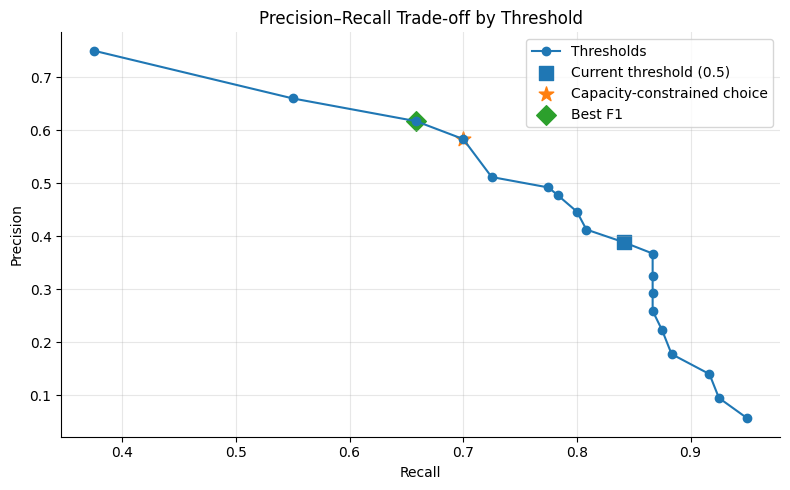

Recommendation: use threshold 0.80 to maximize recall within the 150-alert capacity (144 alerts, recall 70.0%); best F1 is at threshold 0.85 (F1 0.637).


In [5]:
rows = []

# TODO 1: Evaluate thresholds from 0.05 to 0.95
y_true = tx["is_fraud"].to_numpy()
scores = tx["detector_score"].to_numpy()

for threshold in np.arange(0.05, 1.00, 0.05):
    predicted = scores >= threshold

    alerts = int(predicted.sum())
    TP = int(((predicted) & (y_true == 1)).sum())
    FP = int(((predicted) & (y_true == 0)).sum())
    FN = int(((~predicted) & (y_true == 1)).sum())

    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0
    f1 = (2 * precision * recall / (precision + recall)
          if precision + recall else 0)

    rows.append({
        "threshold": round(float(threshold), 2),
        "alerts": alerts,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "precision": precision,
        "recall": recall,
        "F1": f1
    })

pr = pd.DataFrame(rows)

# TODO 2: Capacity-constrained choice and best-F1 choice
eligible = pr[pr["alerts"] <= 150]
capacity_choice = eligible.sort_values(
    ["recall", "threshold"], ascending=[False, False]
).iloc[0]

best_f1 = pr.loc[pr["F1"].idxmax()]

# TODO 3: Precision–recall curve and selected thresholds
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pr["recall"], pr["precision"], marker="o", label="Thresholds")

current = pr.iloc[(pr["threshold"] - 0.5).abs().argmin()]
ax.scatter(current["recall"], current["precision"], s=100,
           marker="s", label="Current threshold (0.5)")

ax.scatter(capacity_choice["recall"], capacity_choice["precision"],
           s=120, marker="*", label="Capacity-constrained choice")

ax.scatter(best_f1["recall"], best_f1["precision"],
           s=100, marker="D", label="Best F1")

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision–Recall Trade-off by Threshold")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

# TODO 4: One-line recommendation
print(
    f"Recommendation: use threshold {capacity_choice['threshold']:.2f} "
    f"to maximize recall within the 150-alert capacity "
    f"({int(capacity_choice['alerts'])} alerts, "
    f"recall {capacity_choice['recall']:.1%}); "
    f"best F1 is at threshold {best_f1['threshold']:.2f} "
    f"(F1 {best_f1['F1']:.3f})."
)

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:The Head of Fraud Ops should make the final decision, not the model. The model provides metrics such as precision, recall, and F1, but the Head must balance investigator capacity, missed fraud, and the cost of false alerts. Visual analytics keeps a human in the loop because domain expertise and operational priorities are needed to steer the threshold and make an accountable decision._

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# TODO 1: Interactive scatter with details-on-demand
flagged = tx[tx["detector_score"] >= 0.3].copy()

fig1 = px.scatter(
    flagged,
    x="timestamp",
    y="amount_inr",
    color="label",
    log_y=True,
    hover_data={
        "txn_id": True,
        "customer_id": True,
        "city": True,
        "merchant_category": True,
        "distance_from_home_km": True,
        "detector_score": ":.4f",
        "timestamp": True,
        "amount_inr": ":.2f"
    },
    title="Flagged Transactions — Select and Inspect Cases",
    labels={
        "timestamp": "Transaction Time",
        "amount_inr": "Amount (INR, log scale)",
        "label": "Transaction Label"
    }
)

fig1.update_layout(dragmode="select")
fig1.show()


# TODO 2: Sunburst drill-down — city → merchant category
sun = (
    tx.groupby(["city", "merchant_category"], as_index=False)
      .agg(
          transaction_count=("txn_id", "count"),
          fraud_count=("is_fraud", "sum")
      )
)

sun["fraud_rate"] = sun["fraud_count"] / sun["transaction_count"]

fig2 = px.sunburst(
    sun,
    path=["city", "merchant_category"],
    values="transaction_count",
    color="fraud_rate",
    color_continuous_scale="Reds",
    hover_data={
        "transaction_count": True,
        "fraud_count": True,
        "fraud_rate": ":.2%"
    },
    title="Transaction Drill-Down: City → Merchant Category",
    labels={
        "transaction_count": "Transactions",
        "fraud_count": "Confirmed Fraud",
        "fraud_rate": "Fraud Rate"
    }
)

fig2.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:Tooltips are frustrating for reviewing 400 flagged cases because investigators must hover over each point individually, increasing interaction time and cognitive load. They cannot easily compare many cases or spot overall patterns at once. The interactive scatter plot fixes this by showing all flagged transactions together, while the sunburst view helps drill down into cities and merchant categories to identify areas with higher fraud rates._

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Hypothesis: confirmed fraud is unusually concentrated in Pune on days 18–20.
Fraud rate inside window:  37.38%
Fraud rate outside window: 1.48%
Chi-square statistic: 619.294
Chi-square p-value: 1.06482e-136

Counter-example search:
                  group  transactions  frauds fraud_rate
                 Window           107      40     37.38%
  Same city, other days           593      11      1.85%
Other cities, same days           457       2      0.44%
                   Rest          4363      67      1.54%


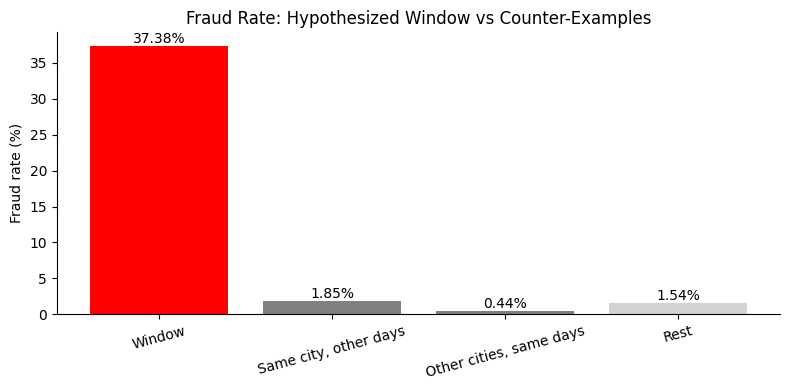

Verdict: SUPPORTS an unusual concentration, but does not prove a fraud ring.


In [7]:
from scipy.stats import chi2_contingency

# TODO 1: Define the hypothesis using the highest-fraud cell from Task 1
top_cell = top_cells.index[0]
target_city = top_cell[0]
peak_day = int(top_cell[1])
day_start = max(int(tx["day"].min()), peak_day - 1)
day_end = min(int(tx["day"].max()), peak_day + 1)

in_window = (
    (tx["city"] == target_city) &
    (tx["day"].between(day_start, day_end))
)

print(
    f"Hypothesis: confirmed fraud is unusually concentrated in "
    f"{target_city} on days {day_start}–{day_end}."
)

# TODO 2: Fraud rates inside/outside and chi-square test
inside = tx.loc[in_window, "is_fraud"]
outside = tx.loc[~in_window, "is_fraud"]

rate_inside = inside.mean()
rate_outside = outside.mean()

contingency = pd.crosstab(in_window, tx["is_fraud"])
chi2, p_value, dof, expected = chi2_contingency(contingency)

print(f"Fraud rate inside window:  {rate_inside:.2%}")
print(f"Fraud rate outside window: {rate_outside:.2%}")
print(f"Chi-square statistic: {chi2:.3f}")
print(f"Chi-square p-value: {p_value:.6g}")

# TODO 3: Counter-example searches
same_city_other_days = (
    (tx["city"] == target_city) &
    ~tx["day"].between(day_start, day_end)
)
other_cities_same_days = (
    (tx["city"] != target_city) &
    tx["day"].between(day_start, day_end)
)
rest = (
    (tx["city"] != target_city) &
    ~tx["day"].between(day_start, day_end)
)

groups = {
    "Window": in_window,
    "Same city, other days": same_city_other_days,
    "Other cities, same days": other_cities_same_days,
    "Rest": rest
}

summary = pd.DataFrame([
    {
        "group": name,
        "transactions": int(mask.sum()),
        "frauds": int(tx.loc[mask, "is_fraud"].sum()),
        "fraud_rate": tx.loc[mask, "is_fraud"].mean()
    }
    for name, mask in groups.items()
])

print("\nCounter-example search:")
print(summary.to_string(index=False, formatters={"fraud_rate": "{:.2%}".format}))

# TODO 4: Visual confirmation
fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(summary["group"], summary["fraud_rate"] * 100,
              color=["red", "grey", "grey", "lightgrey"])

ax.set_ylabel("Fraud rate (%)")
ax.set_title("Fraud Rate: Hypothesized Window vs Counter-Examples")
ax.tick_params(axis="x", rotation=15)

for bar, rate in zip(bars, summary["fraud_rate"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"{rate:.2%}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

# TODO 5: Verdict
counter_rates = summary.loc[summary["group"] != "Window", "fraud_rate"]
if p_value < 0.05 and rate_inside > counter_rates.max():
    verdict = "SUPPORTS an unusual concentration, but does not prove a fraud ring."
elif p_value < 0.05:
    verdict = "A statistical association exists, but counter-examples weaken the ring hypothesis."
else:
    verdict = "INSUFFICIENT statistical evidence for an unusual concentration."

print(f"Verdict: {verdict}")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:The same city on other days search would weaken or kill the hypothesis if its fraud rate were similarly high, suggesting the city has a consistently higher fraud rate rather than a specific fraud-ring event. The other cities on the same days search could also undermine it if their fraud rates were similarly high, suggesting a market-wide or time-related spike rather than a city-specific ring._

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:Last month, the system recorded **5,520 transactions, including 120 confirmed fraud cases**, and the city–day heatmap helped identify potential fraud concentrations that require further investigation. I recommend using the threshold that maximizes recall while keeping alerts at or below the team’s capacity of **150 alerts**, balancing fraud detection against false alarms; the Head of Fraud Ops should make the final decision using precision, recall, and F1. The first interactive tool should be a **Plotly scatter plot of flagged transactions**, enabling investigators to select cases and inspect transaction details through tooltips, following the principles of dynamic queries and details-on-demand. Filtering and rendering should be optimized to meet the **0.1-second response budget** so interactions feel immediate. Finally, implement a **human feedback loop** in which investigators label confirmed fraud and false positives, and those reviewed outcomes are fed back into detector training and evaluation to improve next month’s model._